# Тупики и иллюзии в данных: Leakage, сломанная закладка и $10^k > P$

Перед публикацией собрал в одном блокноте три наглядных «ловушки», которые встретились по ходу работы:
1. **Иллюзия «взлома $\pi$» при `shuffle=True`:** если случайно перемешать перекрывающиеся окна длины $L=64$, целевая цифра теста уже присутствует в соседних окнах train, и примитивный поиск сдвинутого суффикса даёт $\sim 80\%$ точности на чистом шуме.
2. **Баг в первой формуле крипто-закладки:** черновая `_legacy_biased_backdoor_v1` алгебраически выродилась в нечётные цифры `{1,3,5,7,9}` и моментально ловилась тестом $\chi^2$, тогда как биективная `apply_csprng_backdoor` маскируется под идеальный шум.
3. **Почему на `1/97` не сработал фазовый переход на $L=64 \to 128$:** правило $10^k > P$ гарантирует 100% уникальность подстрок длины $k$ для `1/7`, `1/19`, `1/97` и `1/997`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import Image, display
from scipy import stats

from src.data_generator import (
    _legacy_biased_backdoor_v1,
    apply_csprng_backdoor,
    generate_constant_digits,
    generate_rational_digits,
)
from src.dataset import split_sequence_chronologically, verify_zero_leakage

ROOT_DIR = Path.cwd().resolve()
if not (ROOT_DIR / 'src').exists() and (ROOT_DIR.parent / 'src').exists():
    ROOT_DIR = ROOT_DIR.parent
rng = np.random.default_rng(42)
cache_pi = ROOT_DIR / 'data' / 'true_pi_digits.npy'
pi_50k = np.load(cache_pi)[:50_000].copy() if cache_pi.exists() else generate_constant_digits('pi', 50_000, 10)
print(f'Загружено цифр pi: {len(pi_50k):,}, первые 30: {"".join(map(str, pi_50k[:30]))}')

Загружено цифр pi: 50,000, первые 30: 141592653589793238462643383279


## A. Иллюзия предсказуемости при случайном `shuffle=True` против хронологического сплита

,Режим сплита,Пересечение индексов (%),Сдвинутых совпадений (%),Accuracy (%)
0,Случайный shuffle=True,100.0,0.0,10.04
1,Хронологический (verify_zero_leakage),0.0,0.0,10.31


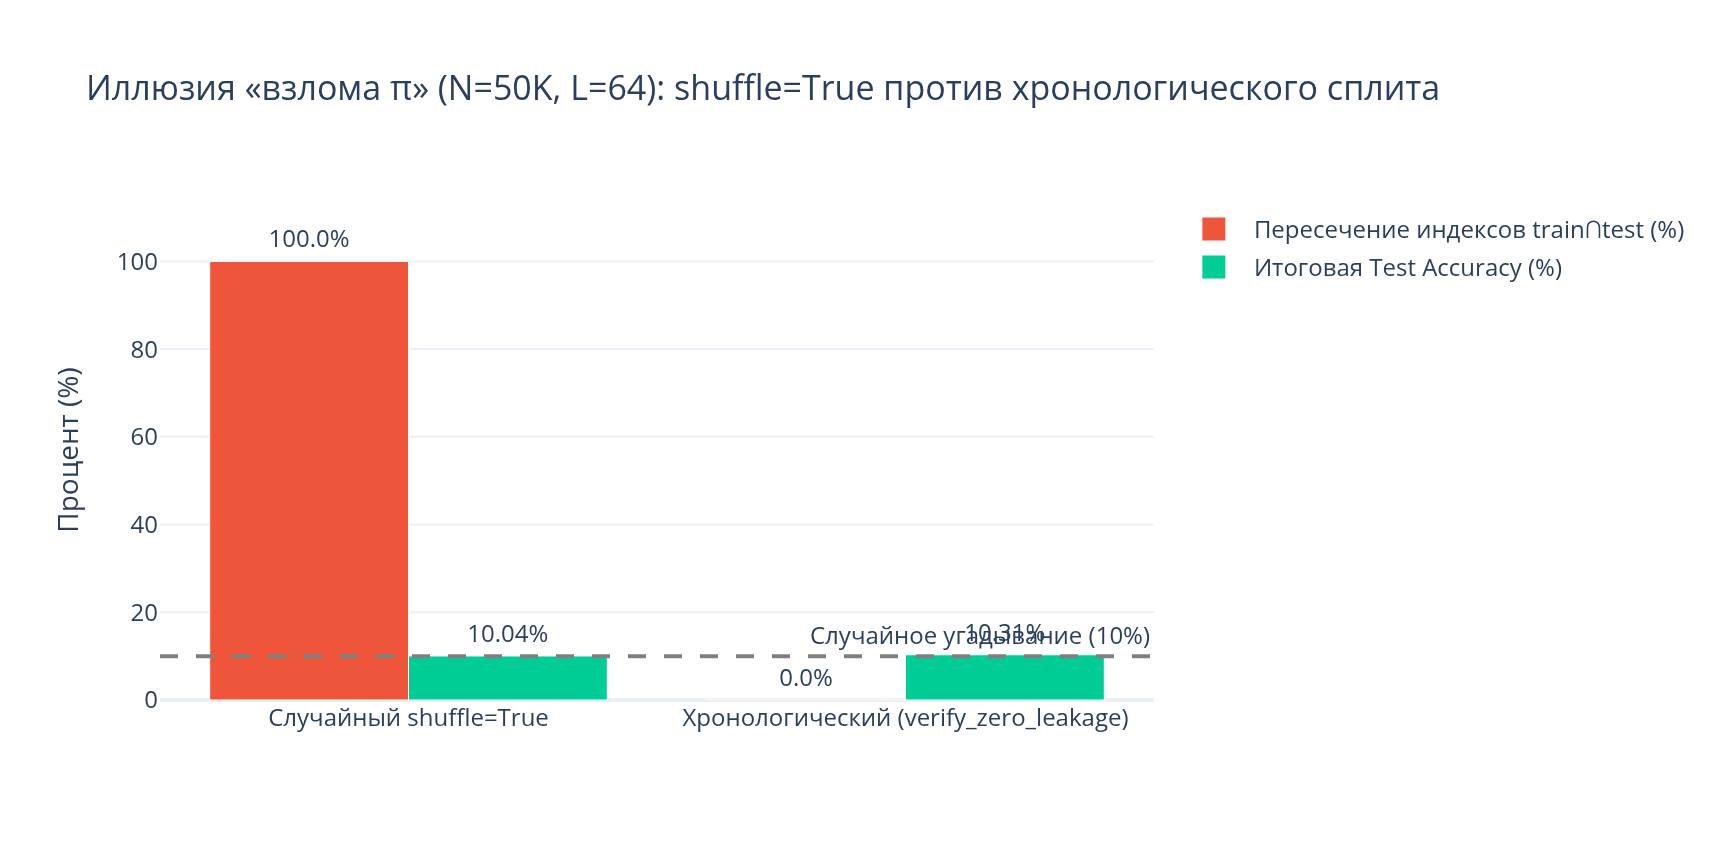

In [2]:
L = 64
windows = np.lib.stride_tricks.sliding_window_view(pi_50k, L + 1)
raw_indices = np.lib.stride_tricks.sliding_window_view(np.arange(len(pi_50k)), L + 1)

# 1. Дырявый сплит (shuffle=True по окнам 80/20)
perm = rng.permutation(len(windows))
n_tr = int(0.8 * len(windows))
tr_w, te_w = windows[perm[:n_tr]], windows[perm[n_tr:]]
tr_idx = set(raw_indices[perm[:n_tr], :-1].ravel().tolist())
te_tgt_idx = raw_indices[perm[n_tr:], -1].tolist()
leak_index_overlap = 100.0 * sum(1 for t in te_tgt_idx if t in tr_idx) / len(te_tgt_idx)

# Простой суффикс-детектор: ищем окно в train, где x_train[:-1] == x_test[1:] (сдвиг на 1 шаг)
def eval_shift_detector(train_win, test_win):
    lookup = {train_win[i, :-1].tobytes(): int(train_win[i, -1]) for i in range(len(train_win))}
    hits, matched = 0, 0
    for i in range(len(test_win)):
        key = test_win[i, 1:-1].tobytes()
        pred = lookup.get(key)
        if pred is not None:
            matched += 1
        else:
            pred = 0  # фоллбэк на дефолтную цифру
        if pred == int(test_win[i, -1]):
            hits += 1
    return 100.0 * hits / len(test_win), 100.0 * matched / len(test_win)

shuf_acc, shuf_match = eval_shift_detector(tr_w, te_w)

# 2. Честный хронологический сплит (80/10/10 -> без пересечения индексов)
split = split_sequence_chronologically(pi_50k, mask=None, train_ratio=0.8, val_ratio=0.1, test_ratio=0.1)
leak_rep = verify_zero_leakage(split, window_size=L)
ch_tr_w = np.lib.stride_tricks.sliding_window_view(split.train_digits, L + 1)
ch_te_w = np.lib.stride_tricks.sliding_window_view(split.test_digits, L + 1)
chrono_acc, chrono_match = eval_shift_detector(ch_tr_w, ch_te_w)
chrono_overlap = 0.0

leak_df = pd.DataFrame([
    {'Режим сплита': 'Случайный shuffle=True', 'Пересечение индексов (%)': round(leak_index_overlap, 2), 'Сдвинутых совпадений (%)': round(shuf_match, 2), 'Accuracy (%)': round(shuf_acc, 2)},
    {'Режим сплита': 'Хронологический (verify_zero_leakage)', 'Пересечение индексов (%)': chrono_overlap, 'Сдвинутых совпадений (%)': round(chrono_match, 2), 'Accuracy (%)': round(chrono_acc, 2)},
])
display(leak_df)

fig_leak = go.Figure([
    go.Bar(name='Пересечение индексов train∩test (%)', x=leak_df['Режим сплита'], y=leak_df['Пересечение индексов (%)'], marker_color='#EF553B', text=leak_df['Пересечение индексов (%)'].map(lambda v: f'{v:.1f}%'), textposition='outside'),
    go.Bar(name='Итоговая Test Accuracy (%)', x=leak_df['Режим сплита'], y=leak_df['Accuracy (%)'], marker_color='#00CC96', text=leak_df['Accuracy (%)'].map(lambda v: f'{v:.2f}%'), textposition='outside'),
])
fig_leak.add_hline(y=10.0, line_dash='dash', line_color='gray', annotation_text='Случайное угадывание (10%)')
fig_leak.update_layout(title='Иллюзия «взлома π» (N=50K, L=64): shuffle=True против хронологического сплита', barmode='group', yaxis=dict(title='Процент (%)', range=[0, 114]), template='plotly_white', width=860, height=430)
display(Image(fig_leak.to_image(format='png', width=860, height=430, scale=2)))

## B. Почему сломалась черновая крипто-закладка `_legacy_biased_backdoor_v1`

Legacy V1: маска=1.02%, уникальные цифры на триггере=[1, 3, 5, 7, 9], full chi2 p=5.667e-01
Bijective: маска=4.03%, уникальные цифры на триггере=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9], full chi2 p=0.3980


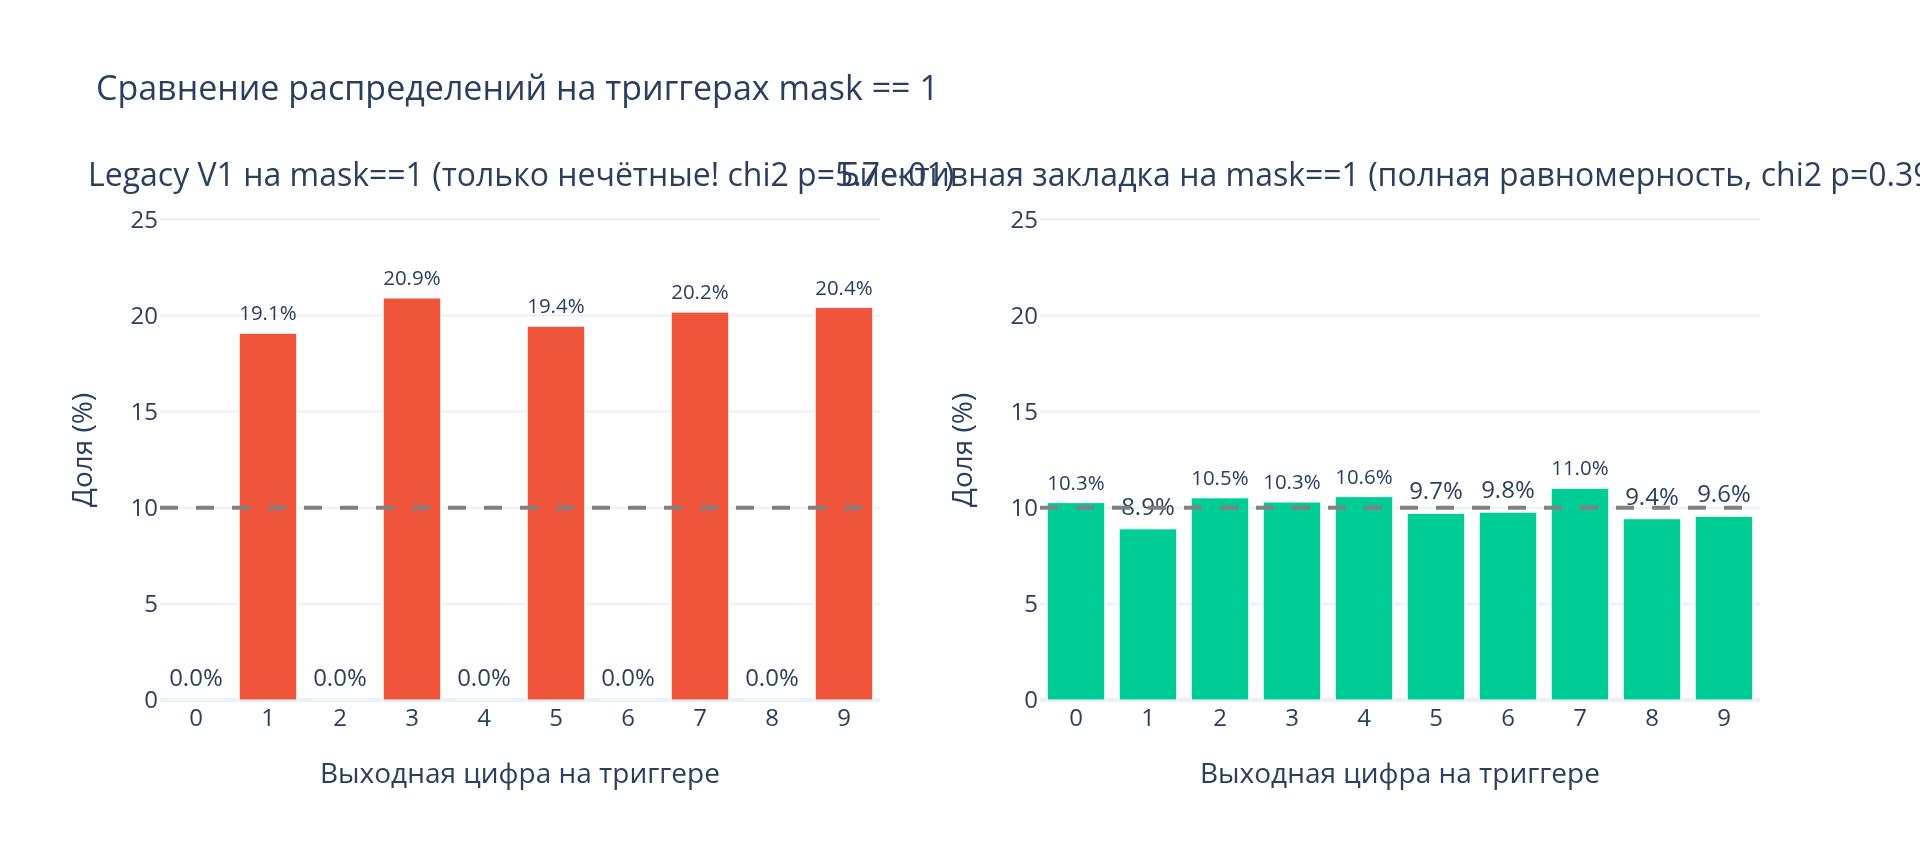

In [3]:
noise_80k = rng.integers(0, 10, size=80_000, dtype=np.uint8)
leg_d, leg_m = _legacy_biased_backdoor_v1(noise_80k, lag1=24, lag2=7)
bij_d, bij_m = apply_csprng_backdoor(noise_80k, lag1=24, lag2=7)

leg_trig = leg_d[leg_m == 1]
bij_trig = bij_d[bij_m == 1]
leg_chi_p = stats.chisquare(np.bincount(leg_d, minlength=10)).pvalue
bij_chi_p = stats.chisquare(np.bincount(bij_d, minlength=10)).pvalue
print(f'Legacy V1: маска={leg_m.mean()*100:.2f}%, уникальные цифры на триггере={np.unique(leg_trig).tolist()}, full chi2 p={leg_chi_p:.3e}')
print(f'Bijective: маска={bij_m.mean()*100:.2f}%, уникальные цифры на триггере={np.unique(bij_trig).tolist()}, full chi2 p={bij_chi_p:.4f}')

leg_pct = 100.0 * np.bincount(leg_trig, minlength=10) / len(leg_trig)
bij_pct = 100.0 * np.bincount(bij_trig, minlength=10) / len(bij_trig)
fig_bd = make_subplots(rows=1, cols=2, subplot_titles=(f'Legacy V1 на mask==1 (только нечётные! chi2 p={leg_chi_p:.1e})', f'Биективная закладка на mask==1 (полная равномерность, chi2 p={bij_chi_p:.3f})'))
fig_bd.add_trace(go.Bar(x=list(range(10)), y=leg_pct, marker_color='#EF553B', text=[f'{v:.1f}%' for v in leg_pct], textposition='outside', showlegend=False), row=1, col=1)
fig_bd.add_trace(go.Bar(x=list(range(10)), y=bij_pct, marker_color='#00CC96', text=[f'{v:.1f}%' for v in bij_pct], textposition='outside', showlegend=False), row=1, col=2)
for c in (1, 2):
    fig_bd.add_hline(y=10.0, line_dash='dash', line_color='gray', row=1, col=c)
    fig_bd.update_xaxes(title_text='Выходная цифра на триггере', dtick=1, row=1, col=c)
    fig_bd.update_yaxes(title_text='Доля (%)', range=[0, 26], row=1, col=c)
fig_bd.update_layout(title='Сравнение распределений на триггерах mask == 1', template='plotly_white', width=960, height=430)
display(Image(fig_bd.to_image(format='png', width=960, height=430, scale=2)))

## C. Проверка правила $10^k > P$ для периодических дробей `1/7`, `1/19`, `1/97`, `1/997`

In [4]:
rows_p = []
for den, period in [(7, 6), (19, 18), (97, 96), (997, 166)]:
    cyc = generate_rational_digits(1, den, period, radix=10)
    assert np.array_equal(cyc, generate_rational_digits(1, den, period * 2, radix=10)[period:])
    dbl = np.concatenate([cyc, cyc])
    k_min = None
    shares_by_k = {}
    for k in range(1, 7):
        vc = pd.Series([tuple(dbl[i : i + k].tolist()) for i in range(period)]).value_counts()
        uniq_share = float(vc[vc == 1].sum()) / period * 100.0
        shares_by_k[k] = round(uniq_share, 1)
        if k_min is None and uniq_share == 100.0:
            k_min = k
    rows_p.append({
        'Дробь': f'1/{den}',
        'Период P': period,
        'k=1 (%)': shares_by_k[1],
        'k=2 (%)': shares_by_k[2],
        'k=3 (%)': shares_by_k[3],
        'Эмпир. k_min (100%)': k_min,
        'Граница 10^k > P': int(np.ceil(np.log10(period + 1e-9))),
    })

df_p = pd.DataFrame(rows_p)
display(df_p)

,Дробь,Период P,k=1 (%),k=2 (%),k=3 (%),Эмпир. k_min (100%),Граница 10^k > P
0,1/7,6,100.0,100.0,100.0,1,1
1,1/19,18,11.1,100.0,100.0,2,2
2,1/97,96,0.0,100.0,100.0,2,2
3,1/997,166,0.0,15.7,100.0,3,3
